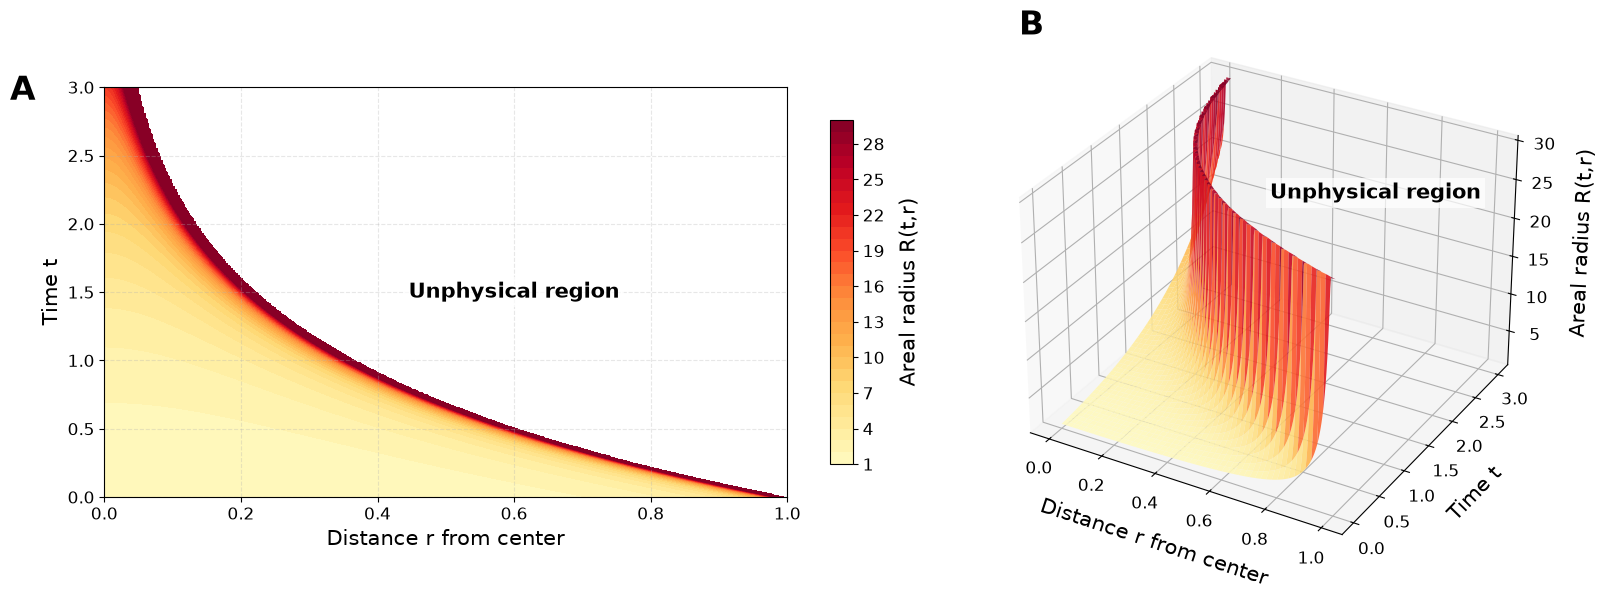

In [6]:
# MIT License
# Copyright (c) 2026 T.H.Günther, mail@gnthr.de

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

L = -1

def R(r, t):
    return np.exp(t) / (1 + L * (np.exp(2 * t) * r**2))

r_vals = np.linspace(0, 1, 400)
t_vals = np.linspace(0, 3, 400)

fs1=12
fs2 = 15

R_grid, T_grid = np.meshgrid(r_vals, t_vals)

with np.errstate(divide='ignore', invalid='ignore'):
    Z = R(R_grid, T_grid)

Z[Z <= 0] = np.nan

Z_clipped = np.clip(Z, 0, 30)

fig = plt.figure(figsize=(17, 6))

max_val = 30  
norm = mcolors.Normalize(vmin=0, vmax=max_val)

ax1 = fig.add_subplot(1, 2, 1)
contour = ax1.contourf(R_grid, T_grid, Z_clipped, levels=30, cmap='YlOrRd', norm=norm)

cbar1 = fig.colorbar(contour, ax=ax1, shrink=0.62, aspect=15)
cbar1.set_label('Areal radius R(t,r)', fontsize=fs2, labelpad=10)
cbar1.ax.tick_params(labelsize=fs1)

ax1.set_xlabel('Distance r from center', fontsize=fs2)
ax1.set_ylabel('Time t', fontsize=fs2)
ax1.tick_params(axis='both', labelsize=fs1)
ax1.grid(True, linestyle='--', alpha=0.3)

ax1.set_aspect(0.2)
ax1.text(0.6, 1.5, 'Unphysical region', fontsize=fs2, fontweight='bold', color='black', 
         ha='center', va='center', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=3))


ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf = ax2.plot_surface(R_grid, T_grid, Z_clipped, cmap='YlOrRd', norm=norm, edgecolor='none', alpha=0.9)



ax2.set_xlabel('Distance r from center', fontsize=fs2, labelpad=10)
ax2.set_ylabel('Time t', fontsize=fs2, labelpad=10)
ax2.set_zlabel('Areal radius R(t,r)', fontsize=fs2, labelpad=10)

ax2.text(0.6, 3, 20, 'Unphysical region', fontsize=fs2, fontweight='bold', color='black', 
         ha='center', va='center', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=3))


ax2.tick_params(axis='both', labelsize=fs1) 
ax2.zaxis.set_tick_params(labelsize=fs1)


def panel_label(ax, label, x=-0.1, y=1.05, fs=24):
    if hasattr(ax, 'text2D'):          # 3D-Achse
        ax.text2D(x, y, label, transform=ax.transAxes,
                  fontsize=fs, fontweight='bold', va='bottom', ha='right')
    else:                              # normale 2D-Achse
        ax.text(x, y, label, transform=ax.transAxes,
                fontsize=fs, fontweight='bold', va='bottom', ha='right')

panel_label(ax1, 'A', x=-0.1, y=0.95)
panel_label(ax2, 'B', x=0.1, y=0.95)


plt.subplots_adjust(wspace=-0.1)

plt.savefig("NL_vac3d-ArealR.png", dpi=300, bbox_inches="tight")

plt.tight_layout()
plt.show()